# 04 — Vendor Risk Score & Re-sourcing Scenario

Turns the vendor scorecard (`kpi_vendor_scorecard`) into one **risk score from 0 to 100** per vendor, so procurement knows
which suppliers to act on first, and **why**. Then it estimates what moving volume away from the riskiest vendors would do
to delivery performance, lead time and cost.

**Method**

| Component | Metric | Weight | Group |
|---|---|---:|---|
| Delivery | 100 − on-time delivery % | 25% | Performance |
| Delay severity | Average days late (late lines) | 10% | Performance |
| Lead-time variability | Coefficient of variation of lead time | 10% | Performance |
| Quality | % of receipts with rejections | 20% | Performance |
| Deterioration | Drop in on-time % vs the previous year | 10% | Performance |
| Price | Price premium vs market benchmark | 5% | Performance |
| Category dependency | Vendor's share of its category's spend | 15% | Exposure |
| Single-source dependency | % of the vendor's items with no other supplier | 5% | Exposure |

Each metric is scaled 0–100 between its 5th and 95th percentile across vendors (values beyond are capped), so one
extreme vendor can't squash everyone else's scores. Only vendors with **≥ 30 PO lines due** are scored; the rest are
marked *insufficient data*.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sqlalchemy import text

from db import get_engine
from utils import REPORTS_DIR, ROOT
from viz_style import INK_2, MUTED, SERIES, apply_style, save, subtitle

apply_style()
engine = get_engine()
RISK_DIR = REPORTS_DIR / "risk"
RISK_DIR.mkdir(exist_ok=True)


def q(sql, dates=()):
    df = pd.read_sql(text(sql), engine)
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df


pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Inputs

In [2]:
sc = q("SELECT * FROM kpi_vendor_scorecard")
num = sc.columns.drop(["vendor_id", "vendor_name", "vendor_category", "vendor_state"])
sc[num] = sc[num].astype(float)

single = q("SELECT only_vendor AS vendor_id, COUNT(*) AS single_source_items FROM kpi_single_source_items GROUP BY only_vendor")
n_items = q("SELECT vendor_id, COUNT(DISTINCT item_id) AS items_supplied FROM purchase_orders GROUP BY vendor_id")
sc = sc.merge(single, on="vendor_id", how="left").merge(n_items, on="vendor_id", how="left")
sc["single_source_items"] = sc.single_source_items.fillna(0)

sc["category_share_pct"] = sc.spend_crore / sc.groupby("vendor_category").spend_crore.transform("sum") * 100
sc["single_source_share_pct"] = sc.single_source_items / sc.items_supplied * 100
sc["lead_time_cv"] = sc.lead_time_sd_days / sc.avg_lead_time_days
sc["otd_change_pp"] = sc.otd_last_year_pct - sc.otd_prev_year_pct

eligible = sc.lines_due >= 30
print(f"Vendors scored: {eligible.sum()} of {len(sc)} (others have < 30 lines due)")

Vendors scored: 148 of 150 (others have < 30 lines due)


## 2. Risk score

In [3]:
COMPONENTS = {  # name: (risk metric where higher = riskier, weight, group)
    "delivery":         (100 - sc.otd_pct,                0.25, "performance"),
    "delay_severity":   (sc.avg_delay_days,               0.10, "performance"),
    "lead_variability": (sc.lead_time_cv,                 0.10, "performance"),
    "quality":          (sc.receipts_with_rejection_pct,  0.20, "performance"),
    "deterioration":    (-sc.otd_change_pp,               0.10, "performance"),
    "price":            (sc.price_vs_market_pct,          0.05, "performance"),
    "category_dependency":      (sc.category_share_pct,      0.15, "exposure"),
    "single_source_dependency": (sc.single_source_share_pct, 0.05, "exposure"),
}


def scale(x, mask):
    lo, hi = x[mask].quantile(0.05), x[mask].quantile(0.95)
    return ((x - lo) / (hi - lo)).clip(0, 1) * 100


def score(weights):
    total = sum(weights.values())
    return sum(sc[f"c_{name}"] * w for name, w in weights.items()) / total


for name, (metric, weight, group) in COMPONENTS.items():
    sc[f"c_{name}"] = scale(metric.fillna(metric[eligible].median()), eligible)

weights = {n: w for n, (_, w, _) in COMPONENTS.items()}
sc["performance_score"] = score({n: w for n, (_, w, g) in COMPONENTS.items() if g == "performance"})
sc["exposure_score"] = score({n: w for n, (_, w, g) in COMPONENTS.items() if g == "exposure"})
sc["risk_score"] = score(weights)

contrib = pd.DataFrame({n: sc[f"c_{n}"] * w for n, w in weights.items()})
sc["main_driver"] = contrib.idxmax(axis=1).str.replace("_", " ")

sc.loc[~eligible, ["performance_score", "exposure_score", "risk_score"]] = np.nan
sc.loc[~eligible, "main_driver"] = ""

# Red flags: a severe problem on one critical dimension makes a vendor High risk on its own,
# even if a weighted average would dilute it (knock-out criteria, as in supplier-risk frameworks)
RED_FLAG_AT = 90
red = {"delivery": "very poor delivery", "quality": "very high rejections", "deterioration": "sharp decline"}
sc["red_flags"] = [", ".join(label for comp, label in red.items() if row[f"c_{comp}"] >= RED_FLAG_AT)
                   for _, row in sc.iterrows()]
sc.loc[~eligible, "red_flags"] = ""
sc["risk_tier"] = np.select([~eligible, (sc.risk_score >= 50) | (sc.red_flags != ""), sc.risk_score >= 35],
                            ["Insufficient data", "High", "Medium"], "Low")
sc["risk_rank"] = sc.risk_score.rank(ascending=False, method="first")

print(sc[eligible].risk_score.describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
tiers = sc.groupby("risk_tier").agg(vendors=("vendor_id", "size"), spend_crore=("spend_crore", "sum"))
tiers["spend_share_%"] = tiers.spend_crore / tiers.spend_crore.sum() * 100
tiers.reindex(["High", "Medium", "Low", "Insufficient data"])

count   148.00
mean     34.90
std      13.10
min      10.60
25%      25.00
50%      32.00
75%      43.90
90%      52.60
max      77.20


,vendors,spend_crore,spend_share_%
risk_tier,,,
High,38,700.94,45.51
Medium,31,281.03,18.25
Low,79,557.80,36.22
Insufficient data,2,0.28,0.02


**Tiers**

| Tier | Rule |
|---|---|
| High | Score ≥ 50, **or** any red flag |
| Medium | Score 35–50 |
| Low | Score below 35 |

- A score of 50 means a vendor sits, on weighted average, halfway between the best and worst 5% of vendors on every risk metric.
- A **red flag** is raised when delivery, quality or deterioration alone scores ≥ 90, i.e. the vendor is among the worst on that
  dimension. Without it, a vendor with severe quality problems but good delivery would be averaged down to Low.

In [4]:
show = ["risk_rank", "vendor_id", "vendor_name", "vendor_category", "spend_crore", "risk_score", "risk_tier", "red_flags",
        "main_driver", "otd_pct", "otd_change_pp", "receipts_with_rejection_pct", "category_share_pct"]
print("Red-flag vendors:", (sc.red_flags != "").sum(), "| of which High only because of the flag:",
      ((sc.red_flags != "") & (sc.risk_score < 50)).sum())
top = sc[eligible].sort_values("risk_score", ascending=False)
top[show].head(15)

Red-flag vendors: 30 | of which High only because of the flag: 18


,risk_rank,vendor_id,vendor_name,vendor_category,spend_crore,risk_score,risk_tier,red_flags,main_driver,otd_pct,otd_change_pp,receipts_with_rejection_pct,category_share_pct
101,1.00,V102,Global Industrial Services Pvt Ltd,MRO,24.58,77.24,High,very poor delivery,delivery,51.31,2.44,5.61,29.65
46,2.00,V047,Modern Pack Solutions & Co,Packaging,28.90,69.92,High,,delivery,55.50,0.78,3.66,31.87
105,3.00,V106,Agarwal Systems Ltd,IT Hardware,63.88,68.64,High,very poor delivery,delivery,49.12,-1.85,2.25,36.99
92,4.00,V093,Balaji Hardware Pvt Ltd,MRO,5.90,66.27,High,very poor delivery,delivery,51.21,6.96,4.82,7.11
43,5.00,V044,Om Cartons Pvt Ltd,Packaging,14.46,62.88,High,very poor delivery,delivery,53.72,0.50,4.16,15.95
145,6.00,V146,Bharat Traders & Co,Office Supplies,0.35,62.25,High,very poor delivery,delivery,42.86,-2.22,4.60,2.10
138,7.00,V139,Modern Office Solutions & Co,Office Supplies,2.79,59.57,High,,category dependency,75.73,1.23,7.30,16.59
10,8.00,V011,Sai Ispat Ltd,Raw Materials,8.94,57.63,High,very poor delivery,delivery,32.35,-10.15,6.48,1.00
137,9.00,V138,Western Stationers Industries,Office Supplies,1.44,57.41,High,,quality,76.94,-9.98,7.69,8.57
90,10.00,V091,Malhotra Hardware LLP,MRO,0.99,57.36,High,very poor delivery,delivery,49.02,3.28,3.81,1.20


## 3. Risk matrix: performance vs exposure

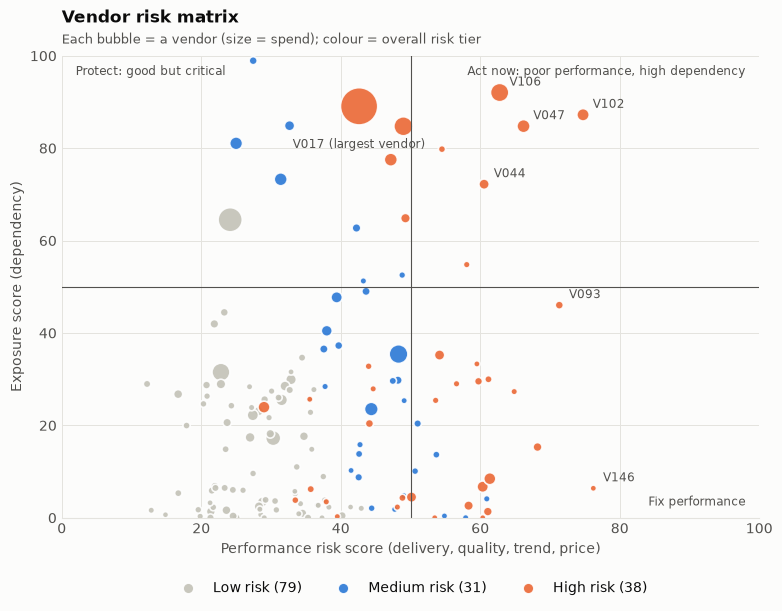

In [5]:
e = sc[eligible]
fig, ax = plt.subplots(figsize=(9, 6))
colors = {"High": SERIES[1], "Medium": SERIES[0], "Low": MUTED}
for tier in ["Low", "Medium", "High"]:
    t = e[e.risk_tier == tier]
    ax.scatter(t.performance_score, t.exposure_score, s=20 + t.spend_crore / e.spend_crore.max() * 700,
               color=colors[tier], edgecolor="white", lw=1.2, alpha=0.9, label=f"{tier} risk ({len(t)})")
for _, v in e.nlargest(6, "risk_score").iterrows():
    ax.annotate(v.vendor_id, (v.performance_score, v.exposure_score), xytext=(7, 5), textcoords="offset points",
                color=INK_2, fontsize=8.5)
big = e.loc[e.spend_crore.idxmax()]
ax.annotate(f"{big.vendor_id} (largest vendor)", (big.performance_score, big.exposure_score), xytext=(0, -30),
            textcoords="offset points", ha="center", color=INK_2, fontsize=8.5)
ax.axvline(50, color=INK_2, lw=0.8)
ax.axhline(50, color=INK_2, lw=0.8)
for x, y, s in [(98, 98, "Act now: poor performance, high dependency"), (98, 2, "Fix performance"),
                (2, 98, "Protect: good but critical")]:
    ax.text(x, y, s, color=INK_2, fontsize=8.5, ha="right" if x > 50 else "left", va="top" if y > 50 else "bottom")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="Performance risk score (delivery, quality, trend, price)",
       ylabel="Exposure score (dependency)")
legend = ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, markerscale=0.5)
for h in legend.legend_handles:
    h.set_sizes([60])
ax.set_title("Vendor risk matrix")
subtitle(ax, "Each bubble = a vendor (size = spend); colour = overall risk tier")
save(fig, "18_vendor_risk_matrix")

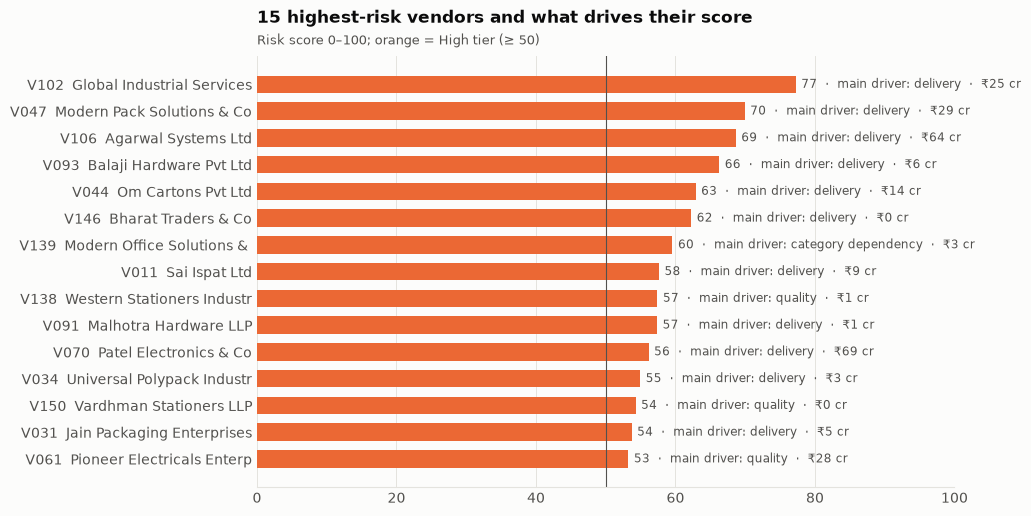

In [6]:
t15 = top.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(t15.vendor_id + "  " + t15.vendor_name.str.slice(0, 26), t15.risk_score,
        color=[SERIES[1] if t == "High" else SERIES[0] for t in t15.risk_tier], height=0.65)
for y, (s, d, sp) in enumerate(zip(t15.risk_score, t15.main_driver, t15.spend_crore)):
    ax.text(s + 0.8, y, f"{s:.0f}  ·  main driver: {d}  ·  ₹{sp:.0f} cr", va="center", color=INK_2, fontsize=8.5)
ax.set_xlim(0, 100)
ax.axvline(50, color=INK_2, lw=0.8)
ax.grid(axis="y", visible=False)
ax.set_title("15 highest-risk vendors and what drives their score")
subtitle(ax, "Risk score 0–100; orange = High tier (≥ 50)")
save(fig, "19_top_risk_vendors")

## 4. How sensitive is the ranking to the weights?

Weights are a judgement call, so the score should not hinge on them. Two alternatives are compared with the chosen weights:
equal weights for all eight components, and a delivery-heavy version (delivery 40%).

In [7]:
alt = {
    "equal weights": {n: 1 for n in weights},
    "delivery-heavy": {**weights, "delivery": 0.40},
}
rows = []
base_top10 = set(top.head(10).vendor_id)
for name, w in alt.items():
    s = score(w)[eligible]
    alt_top10 = set(sc.loc[s.sort_values(ascending=False).index[:10], "vendor_id"])
    rows.append({"alternative": name,
                 "rank_correlation": sc.loc[eligible, "risk_score"].corr(s, method="spearman"),
                 "top10_overlap": len(base_top10 & alt_top10)})
pd.DataFrame(rows)

,alternative,rank_correlation,top10_overlap
0,equal weights,0.90,8
1,delivery-heavy,0.98,8


## 5. Scenario: re-source the 10 largest High-risk vendors

**Question:** if the 2025 volume of the 10 High-risk vendors with the most spend had gone to qualified alternatives,
what would have changed?

**Rules**
- An alternative must have supplied **the same item** before (so it is already qualified for it).
- It must be in the **Low or Medium** tier and have ≥ 30 lines due.
- It must deliver on time **at least as often** as the current vendor.
- **Capacity limit:** an alternative can take at most **+50%** of its own 2025 volume.
- Lines are assigned largest first, each to the alternative with the best on-time rate that still has room.
- Lines with no qualified alternative, or no capacity left, stay where they are.

**Measures**
- Expected on-time rate and lead time use each vendor's own historical rates.
- The cost effect uses each vendor's price premium vs market.
- The capacity check shows how much each alternative's volume would grow.

In [8]:
lines = q('''
SELECT po_id, line_no, order_date, vendor_id, item_id, category, line_value, is_due, is_on_time, lead_time_days
FROM v_po_lines WHERE YEAR(order_date) = (SELECT YEAR(cutoff_date) FROM v_params)
''', dates=["order_date"])
lines["line_value"] = lines.line_value.astype(float)
supplied = q("SELECT DISTINCT item_id, vendor_id FROM purchase_orders")

CAPACITY_UPLIFT = 0.50
risky = sc[sc.risk_tier == "High"].nlargest(10, "spend_crore").vendor_id.tolist()
ok = sc[eligible & sc.risk_tier.isin(["Low", "Medium"])].set_index("vendor_id")
cand = (supplied[supplied.vendor_id.isin(ok.index)].join(ok[["otd_pct"]], on="vendor_id")
        .sort_values("otd_pct", ascending=False).groupby("item_id").vendor_id.apply(list))
room = (lines.groupby("vendor_id").line_value.sum() * CAPACITY_UPLIFT).to_dict()

move = lines[lines.vendor_id.isin(risky)].sort_values("line_value", ascending=False).copy()
current_otd = sc.set_index("vendor_id").otd_pct
alts = []
for item, value, vendor in zip(move.item_id, move.line_value, move.vendor_id):
    choice = next((a for a in cand.get(item, [])
                   if room.get(a, 0) >= value and current_otd[a] >= current_otd[vendor]), None)
    if choice:
        room[choice] -= value
    alts.append(choice)
move["alt_vendor"] = alts
moved = move.dropna(subset=["alt_vendor"]).copy()
print("Vendors re-sourced:", ", ".join(risky))
print(f"2025 lines with these vendors: {len(move):,} (₹{move.line_value.sum() / 1e7:,.1f} cr); "
      f"moved within capacity: {len(moved):,} lines, ₹{moved.line_value.sum() / 1e7:,.1f} cr "
      f"({moved.line_value.sum() / move.line_value.sum():.0%} of value)")

v = sc.set_index("vendor_id")
for col, src in [("otd", "otd_pct"), ("lead", "avg_lead_time_days"), ("price", "price_vs_market_pct")]:
    moved[f"{col}_now"] = moved.vendor_id.map(v[src])
    moved[f"{col}_alt"] = moved.alt_vendor.map(v[src])

due25 = lines[lines.is_due == 1]
otd_now = due25.is_on_time.mean() * 100
m_due = moved[moved.is_due == 1]
late_avoided = ((m_due.otd_alt - m_due.otd_now) / 100).sum()
otd_after = otd_now + late_avoided / len(due25) * 100
lead_now = lines.lead_time_days.mean()
lead_saving_days = (moved.lead_now - moved.lead_alt).sum() / lines.lead_time_days.notna().sum()
cost_delta = (moved.line_value * (moved.price_alt - moved.price_now) / 100).sum()

impact = pd.DataFrame({
    "measure": ["On-time delivery, all 2025 lines (%)", "Late lines avoided (expected)",
                "On-time delivery, re-sourced lines (%)", "Average lead time, all 2025 lines (days)",
                "Average lead time, re-sourced lines (days)", "Cost change from price differences (₹ crore)"],
    "now": [otd_now, np.nan, m_due.otd_now.mean(), lead_now, moved.lead_now.mean(), np.nan],
    "after_resourcing": [otd_after, late_avoided, m_due.otd_alt.mean(), lead_now - lead_saving_days,
                         moved.lead_alt.mean(), cost_delta / 1e7],
})
impact["change"] = impact.after_resourcing - impact.now
impact

Vendors re-sourced: V017, V070, V106, V047, V061, V102, V022, V014, V010, V021
2025 lines with these vendors: 5,303 (₹213.0 cr); moved within capacity: 1,773 lines, ₹101.9 cr (48% of value)


,measure,now,after_resourcing,change
0,"On-time delivery, all 2025 lines (%)",70.89,72.83,1.94
1,Late lines avoided (expected),NaN,341.93,NaN
2,"On-time delivery, re-sourced lines (%)",59.06,79.09,20.03
3,"Average lead time, all 2025 lines (days)",12.19,11.68,-0.50
4,"Average lead time, re-sourced lines (days)",16.09,11.15,-4.94
5,Cost change from price differences (₹ crore),NaN,-1.25,NaN


In [9]:
cap = moved.groupby("alt_vendor").line_value.sum().rename("moved_value").to_frame()
cap["current_2025_value"] = lines.groupby("vendor_id").line_value.sum().reindex(cap.index)
cap["volume_increase_%"] = cap.moved_value / cap.current_2025_value * 100
cap = cap.join(v[["vendor_name", "otd_pct", "risk_tier"]])
print(f"Alternatives used: {len(cap)}; largest volume increase: {cap['volume_increase_%'].max():.0f}% (cap {CAPACITY_UPLIFT:.0%})")
cap.sort_values("moved_value", ascending=False).head(10)

Alternatives used: 83; largest volume increase: 50% (cap 50%)


,moved_value,current_2025_value,volume_increase_%,vendor_name,otd_pct,risk_tier
alt_vendor,,,,,,
V028,"202,629,610.75","405,262,751.51",50.00,Sunrise Metals Pvt Ltd,76.19,Low
V025,"131,611,297.73","263,228,459.94",50.00,Western Steel Industries,83.39,Low
V007,"54,163,304.25","171,714,062.66",31.54,Mehta Alloys Pvt Ltd,76.01,Medium
V013,"35,011,566.68","70,143,309.11",49.91,Gupta Iron & Steel Pvt Ltd,88.27,Low
V024,"34,167,371.62","68,371,404.57",49.97,Joshi Ispat Enterprises,80.18,Low
V111,"28,789,616.72","90,912,257.86",31.67,National IT Solutions Industries,78.90,Medium
V003,"26,144,125.85","65,271,504.75",40.05,Joshi Steel Industries,74.34,Low
V023,"23,768,329.15","47,590,743.40",49.94,Patel Alloys Ltd,77.25,Low
V030,"23,628,835.05","97,612,546.23",24.21,Sunrise Ispat Enterprises,82.96,Low


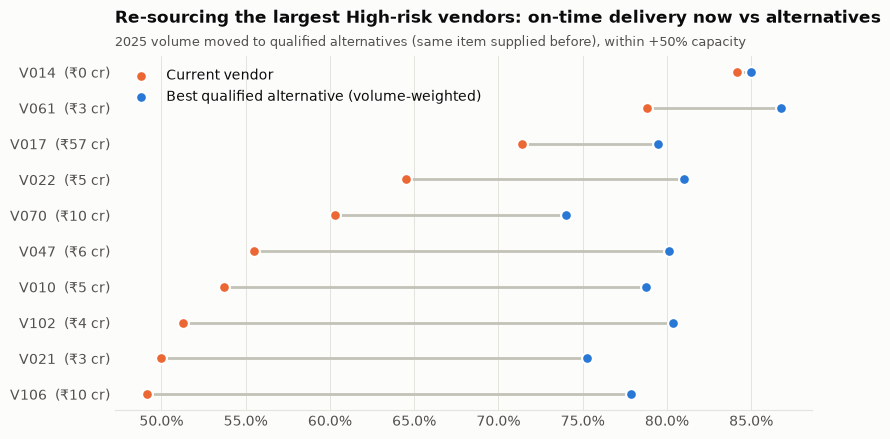

In [10]:
per_vendor = moved.groupby("vendor_id").agg(lines=("po_id", "size"), value_cr=("line_value", lambda x: x.sum() / 1e7),
                                            otd_now=("otd_now", "first"), otd_alt=("otd_alt", "mean")).sort_values("otd_now")
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(per_vendor))
ax.hlines(y, per_vendor.otd_now, per_vendor.otd_alt, color=MUTED, lw=2)
ax.scatter(per_vendor.otd_now, y, color=SERIES[1], s=60, zorder=3, label="Current vendor", edgecolor="white", lw=1.5)
ax.scatter(per_vendor.otd_alt, y, color=SERIES[0], s=60, zorder=3, label="Best qualified alternative (volume-weighted)",
           edgecolor="white", lw=1.5)
ax.set_yticks(y, per_vendor.index + "  (₹" + per_vendor.value_cr.round(0).astype(int).astype(str) + " cr)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(loc="upper left")
ax.grid(axis="y", visible=False)
ax.set_title("Re-sourcing the largest High-risk vendors: on-time delivery now vs alternatives")
subtitle(ax, "2025 volume moved to qualified alternatives (same item supplied before), within +50% capacity")
save(fig, "20_resourcing_scenario")

## 6. Simulation check (only possible because the data is synthetic)

The generator planted vendors with poor delivery, poor quality, or a decline in 2025 (`data/truth/vendor_traits.csv`).
The score never sees these labels. Here they are used only to check whether the score flags those vendors.

In [11]:
traits = pd.read_csv(ROOT / "data" / "truth" / "vendor_traits.csv")
chk = sc[eligible].merge(traits[["vendor_id", "poor_delivery", "poor_quality", "declining_2025"]], on="vendor_id")
chk["planted_problem"] = chk.poor_delivery | chk.poor_quality | chk.declining_2025
rows = []
for col in ["poor_delivery", "poor_quality", "declining_2025", "planted_problem"]:
    g = chk[chk[col]]
    rows.append({"planted group": col, "vendors": len(g), "High": (g.risk_tier == "High").sum(),
                 "High or Medium": g.risk_tier.isin(["High", "Medium"]).sum()})
rows.append({"planted group": "no planted problem", "vendors": (~chk.planted_problem).sum(),
             "High": ((chk.risk_tier == "High") & ~chk.planted_problem).sum(),
             "High or Medium": (chk.risk_tier.isin(["High", "Medium"]) & ~chk.planted_problem).sum()})
pd.DataFrame(rows)

,planted group,vendors,High,High or Medium
0,poor_delivery,22,17,22
1,poor_quality,11,9,10
2,declining_2025,5,4,4
3,planted_problem,38,30,36
4,no planted problem,110,8,33


## 7. Save scores

In [12]:
cols = ["vendor_id", "vendor_name", "vendor_category", "vendor_state", "spend_crore", "lines_due", "risk_rank",
        "risk_score", "risk_tier", "red_flags", "performance_score", "exposure_score", "main_driver"] + \
       [f"c_{n}" for n in COMPONENTS] + \
       ["otd_pct", "otd_change_pp", "avg_delay_days", "lead_time_cv", "receipts_with_rejection_pct",
        "price_vs_market_pct", "category_share_pct", "single_source_share_pct"]
scores = sc[cols].sort_values("risk_rank")
scores.to_sql("vendor_risk_scores", engine, if_exists="replace", index=False)
scores.to_csv(RISK_DIR / "vendor_risk_scores.csv", index=False)
impact.to_csv(RISK_DIR / "resourcing_scenario.csv", index=False)
moved.to_csv(RISK_DIR / "resourcing_scenario_lines.csv", index=False)
print(f"Saved {len(scores)} vendors to procurement_db.vendor_risk_scores and reports/risk/")

Saved 150 vendors to procurement_db.vendor_risk_scores and reports/risk/


## 8. Summary

Full write-up: [`reports/risk_report.md`](../reports/risk_report.md).

- **38 vendors are High risk** and hold 45.5% of spend. The top scores are V102, V047 and V106. V017 is High because of dependency (32% of Raw Materials), not performance.
- **Red flags** stop severe single problems from being averaged away: 30 vendors are flagged, 18 of them High only because of the flag.
- **The ranking is robust:** rank correlation is 0.90–0.98 under alternative weights, and 8 of the top 10 stay the same.
- **Re-sourcing scenario:** ₹101.9 cr can move to qualified, more reliable alternatives within +50% capacity. On that volume, on-time delivery rises from 59% to 79% and lead time falls by 31%, while costing ₹1.25 cr less.
- **Simulation check:** 30 of 38 planted problem vendors scored High, with 8 false alarms among 110 clean vendors.